In [2]:
import pandas as pd
import numpy as np

In [20]:
df = pd.read_csv("2025data.csv")

C:\Users\SuperDraft\AppData\Local\Temp\ipykernel_29900\3979382287.py:1: DtypeWarning: Columns (0: fg_blocked_list) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("2025data.csv")


In [31]:
nfl_wins_2025 = {
    # AFC East
    "NE": 14,
    "BUF": 12,
    "MIA": 7,
    "NYJ": 3,
    # AFC North
    "PIT": 10,
    "BAL": 8,
    "CIN": 6,
    "CLE": 5,
    # AFC South
    "JAX": 13,
    "HOU": 12,
    "IND": 8,
    "TEN": 3,
    # AFC West
    "DEN": 14,
    "LAC": 11,
    "KC": 6,
    "LV": 3,
    # NFC East
    "PHI": 11,
    "DAL": 7,
    "WAS": 5,
    "NYG": 4,
    # NFC North
    "CHI": 11,
    "GB": 9,
    "MIN": 9,
    "DET": 9,
    # NFC South
    "CAR": 8,
    "TB": 8,
    "ATL": 8,
    "NO": 6,
    # NFC West
    "SEA": 14,
    "LA": 12,
    "SF": 12,
    "ARI": 3,
}


In [32]:
wins_df = pd.DataFrame(list(nfl_wins_2025.items()), columns=["team", "wins"])
df = df.merge(wins_df, on="team", how="left")

In [33]:
grouped_by_position = df[df["season_type"]=="REG"].drop(columns=["player_id", "player_name", "player_display_name", "position_group", "headshot_url", "season", "week", "game_id", "opponent_team"])

In [36]:
grouped = grouped_by_position.groupby(["position", "team"]).mean(numeric_only=True).filter(regex='epa|^wins$')

In [37]:
grouped.fillna(0, inplace=True)
grouped["net_epa"] = grouped["passing_epa"] + grouped["rushing_epa"] + grouped["receiving_epa"]
grouped

passing_epa  rushing_epa  receiving_epa  wins   net_epa
position team                                                         
C        ARI      0.000000     0.000000       0.000000   3.0  0.000000
         BAL      0.000000     0.000000       0.000000   8.0  0.000000
         BUF      0.000000     0.000000       0.000000  12.0  0.000000
         CAR      0.000000     0.000000       0.000000   8.0  0.000000
         CHI      0.000000     0.000000       0.000000  11.0  0.000000
...                    ...          ...            ...   ...       ...
WR       SEA     -5.370166     0.216114       1.981355  14.0 -3.172697
         SF       0.000000    -0.164951       0.859128  12.0  0.694177
         TB       0.000000    -0.225306       0.715297   8.0  0.489991
         TEN      0.000000    -0.470518       0.155724   3.0 -0.314794
         WAS     -0.498424     0.094057       0.871488   5.0  0.467121

[556 rows x 5 columns]

<Axes: xlabel='net_epa', ylabel='wins'>

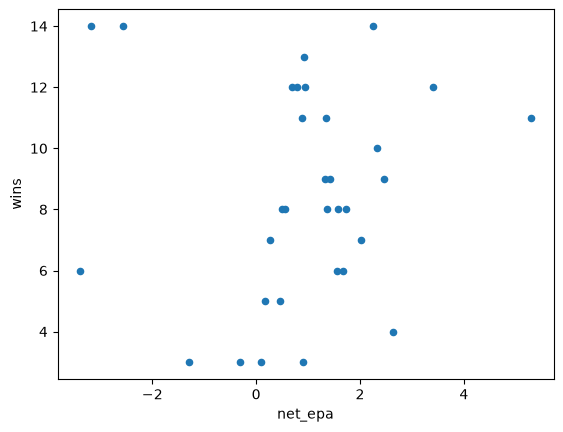

In [40]:
grouped.loc['WR'].plot.scatter(x='net_epa', y='wins')

<Axes: xlabel='receiving_epa', ylabel='wins'>

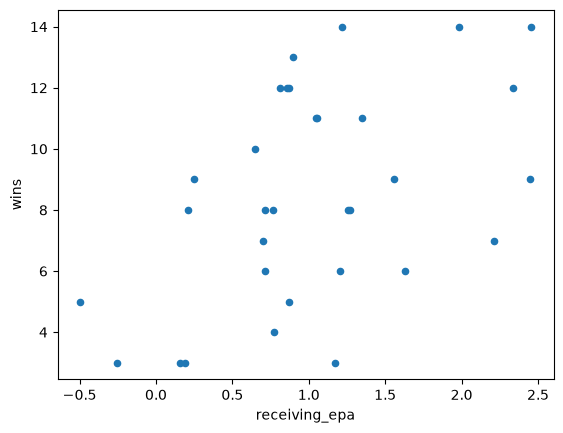

In [41]:
grouped.loc['WR'].plot.scatter(x='receiving_epa', y='wins')

<Axes: xlabel='net_epa', ylabel='wins'>

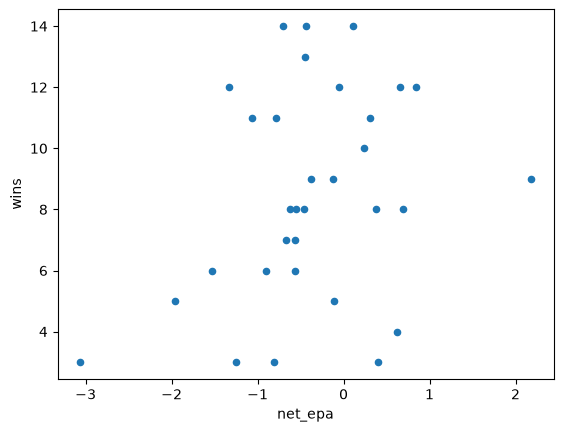

In [42]:
grouped.loc['RB'].plot.scatter(x='net_epa', y='wins')

<Axes: xlabel='rushing_epa', ylabel='wins'>

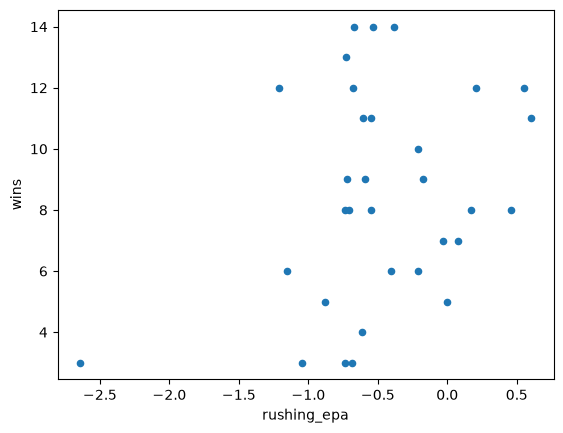

In [43]:
grouped.loc['RB'].plot.scatter(x='rushing_epa', y='wins')

<Axes: xlabel='net_epa', ylabel='wins'>

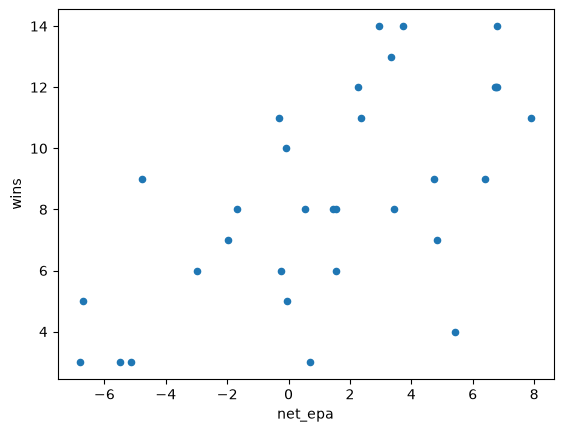

In [44]:
grouped.loc['QB'].plot.scatter(x='net_epa', y='wins')

<Axes: xlabel='passing_epa', ylabel='wins'>

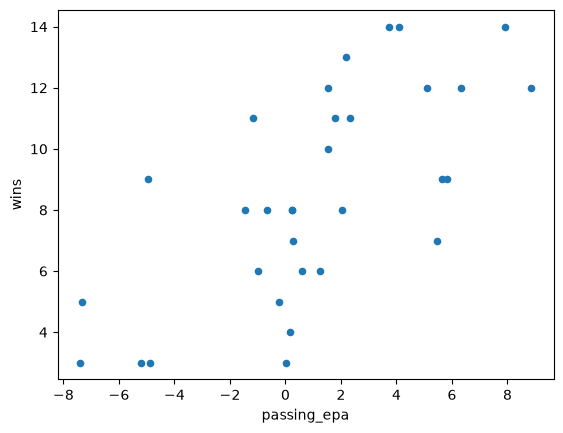

In [45]:
grouped.loc['QB'].plot.scatter(x='passing_epa', y='wins')

<Axes: xlabel='net_epa', ylabel='wins'>

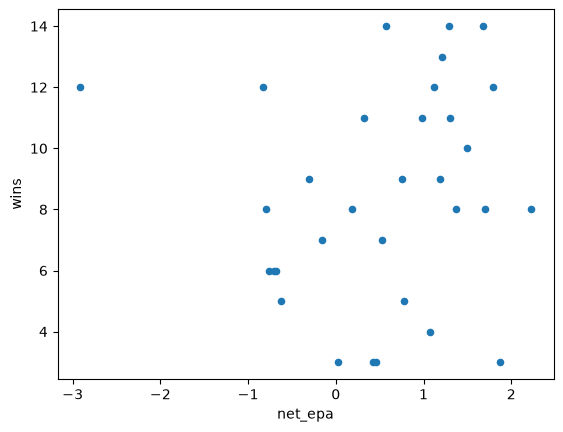

In [46]:
grouped.loc['TE'].plot.scatter(x='net_epa', y='wins')

<Axes: xlabel='receiving_epa', ylabel='wins'>

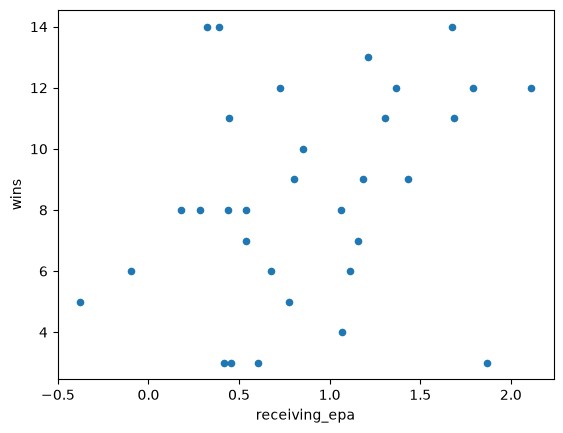

In [47]:
grouped.loc['TE'].plot.scatter(x='receiving_epa', y='wins')

In [58]:
grouped_by_position_for_defense = df[df["season_type"]=="REG"].drop(columns=["player_id", "player_name", "player_display_name", "position_group", "headshot_url", "season", "week", "game_id", "team"])
grouped_defense = grouped_by_position_for_defense.groupby(["position", "opponent_team"]).mean(numeric_only=True).filter(regex='epa')

In [59]:
grouped_defense = grouped_defense.join(wins_df.set_index("team")["wins"], on="opponent_team")

In [62]:
grouped_defense.fillna(0, inplace=True)
grouped_defense["net_epa_allowed"] = grouped_defense["passing_epa"] + grouped_defense["rushing_epa"] + grouped_defense["receiving_epa"]
grouped_defense

passing_epa  rushing_epa  receiving_epa  wins  \
position opponent_team                                                  
C        ARI                    0.0     0.000000       0.000000     3   
         ATL                    0.0     0.000000       0.000000     8   
         BAL                    0.0     0.000000       0.000000     8   
         BUF                    0.0     0.000000       0.000000    12   
         CAR                    0.0     0.000000       0.000000     8   
...                             ...          ...            ...   ...   
WR       SEA                    0.0    -0.073906       0.146311    14   
         SF                     0.0    -0.170431       1.624459    12   
         TB                     0.0    -0.155466       0.678672     8   
         TEN                    0.0     0.610040       2.059139     3   
         WAS                    0.0     0.743059       1.778882     5   

                        net_epa_allowed  
position opponent_team                   
C        ARI                   0.000000  
         ATL                   0.000000  
         BAL                   0.000000  
         BUF                   0.000000  
         CAR                   0.000000  
...                                 ...  
WR       SEA                   0.072404  
         SF                    1.454028  
         TB                    0.523205  
         TEN                   2.669178  
         WAS                   2.521941  

[753 rows x 5 columns]

<Axes: xlabel='receiving_epa', ylabel='wins'>

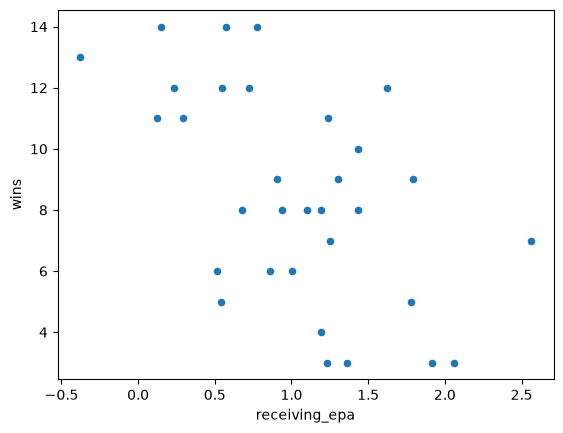

In [65]:
grouped_defense.loc["WR"].plot.scatter(x="receiving_epa", y="wins")

<Axes: xlabel='rushing_epa', ylabel='wins'>

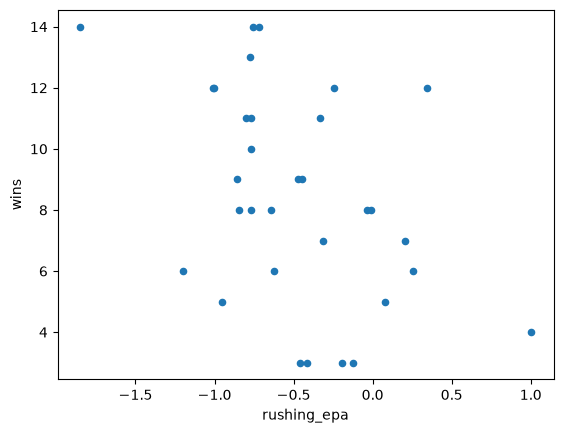

In [66]:
grouped_defense.loc["RB"].plot.scatter(x="rushing_epa", y="wins")

<Axes: xlabel='passing_epa', ylabel='wins'>

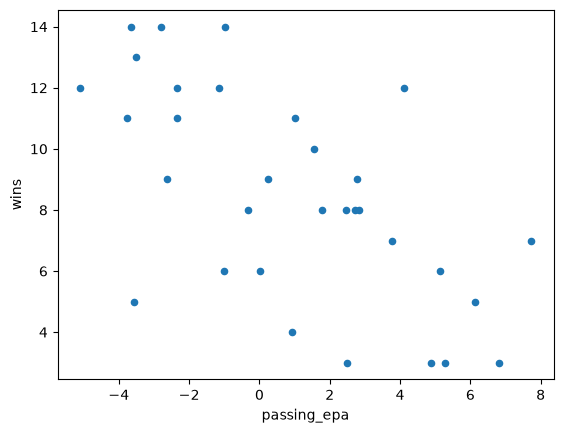

In [67]:
grouped_defense.loc["QB"].plot.scatter(x="passing_epa", y="wins")

<Axes: xlabel='receiving_epa', ylabel='wins'>

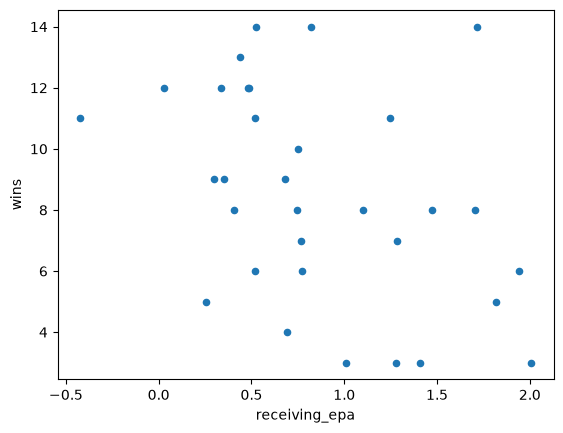

In [68]:
grouped_defense.loc["TE"].plot.scatter(x="receiving_epa", y="wins")